In [5]:
from  data_analysis_example.init_model_ml1 import mlModel


In [6]:
import matplotlib.pyplot as plt
# from data_analysis_example.init_model_ml1 import mlModel
%matplotlib inline

## 1.分群

INFO - infrence...
INFO - load mode success.
INFO - (200000, 45)
INFO - 剩余分类型变量个数：9
INFO - 剩余连续型变量个数：36
INFO - 剩余变量总数：45
INFO - 自定义申请评分卡特征衍生,(200000, 45)
INFO - 剩余分类型变量个数：1
INFO - 剩余连续型变量个数：10
INFO - 剩余变量总数：11
INFO - 异常值3 sigma盖帽处理
INFO - 加载训练集分布成功!
INFO - 异常值处理,(200000, 11)
INFO - 10
INFO - 剩余分类型变量个数：1
INFO - 剩余连续型变量个数：10
INFO - 剩余变量总数：11
INFO - 缺失值填充,(200000, 11)
INFO - number of final features:
INFO - ['n2', 'loanAmnt', 'revolUtil', 'homeOwnership', 'n14', 'verificationStatus', 'ficoRangeHigh', 'interestRate', 'dti', 'annualIncome', 'subGrade']


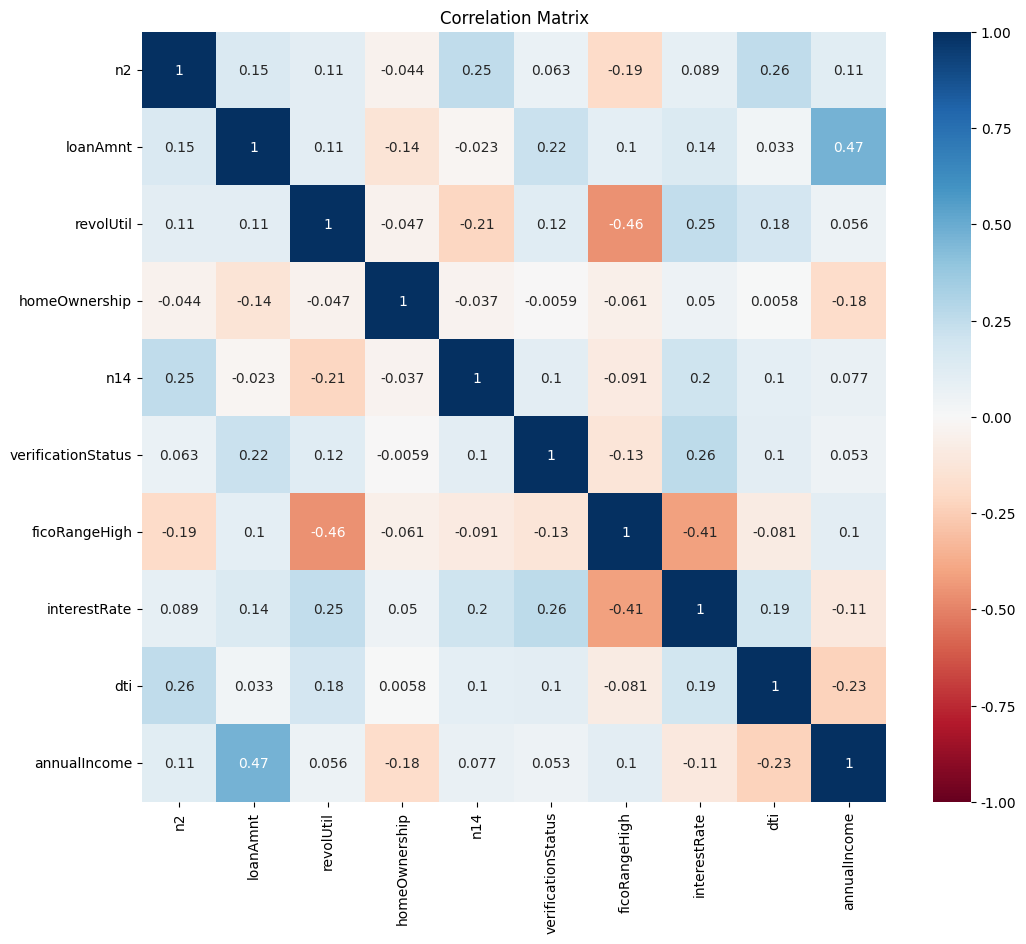

INFO - 剩余分类型变量个数：1
INFO - 剩余连续型变量个数：10
INFO - 剩余变量总数：11
INFO - 剩余分类型变量个数：1
INFO - 剩余连续型变量个数：10
INFO - 剩余变量总数：11
INFO - (200000, 35)
INFO - (200000, 45)


  0%|          | 0/6 [00:00<?, ?it/s]

最小的BIC为-61224544.402002655，最好的K为：5


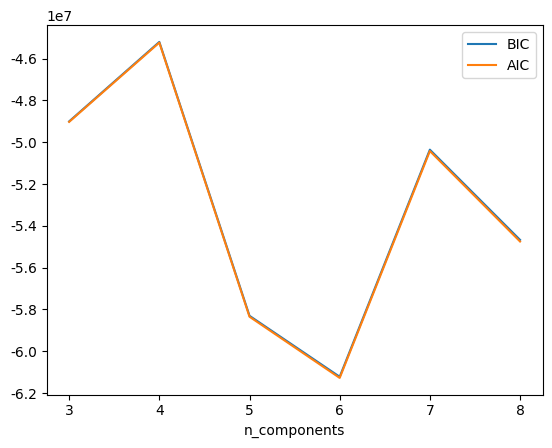

INFO -             BIC
0 -4.900194e+07
1 -4.519708e+07
2 -5.830590e+07
3 -6.122454e+07
4 -5.035419e+07


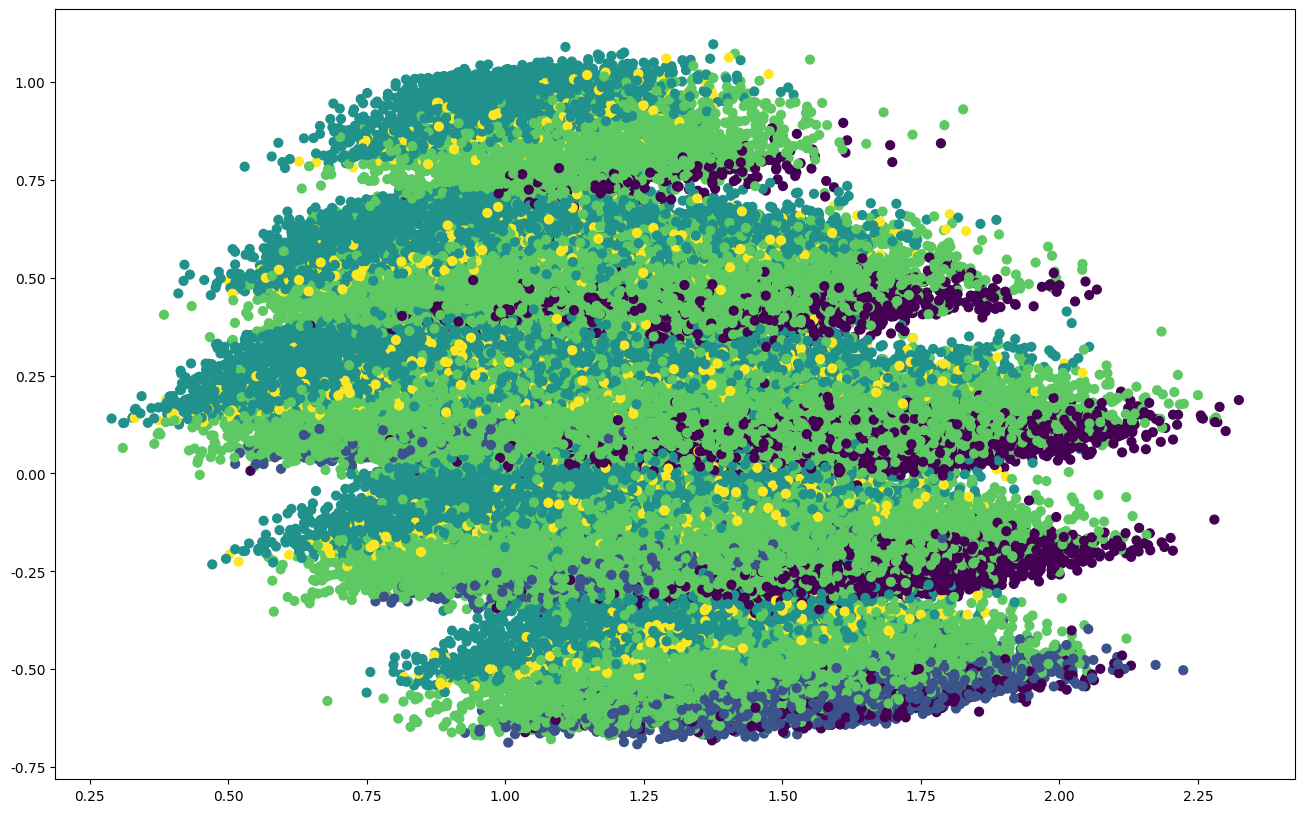

,n2,loanAmnt,revolUtil,homeOwnership,n14,verificationStatus,ficoRangeHigh,interestRate,dti,annualIncome,subGrade,cluster,label
id,,,,,,,,,,,,,
800000,6.0,14000.0,30.7,0.0,3.0,0.0,719.0,10.99,10.56,80000.0,b3,3,1
800001,3.0,20000.0,56.6,0.0,2.0,0.0,674.0,14.65,21.40,50000.0,c5,3,1
800002,4.0,12000.0,17.6,1.0,7.0,2.0,714.0,19.99,33.50,60000.0,d4,3,1
800003,2.0,17500.0,52.3,0.0,3.0,1.0,689.0,14.31,13.95,37000.0,c4,3,1
800004,11.0,35000.0,35.6,1.0,1.0,1.0,689.0,17.09,24.97,80000.0,d1,3,1


In [7]:

cluster_df = mlModel.user_cluster(model_type='lgb',gmm_need_retrain=True,model_size=7,encoder_type='onehot')
cluster_df.head()

## 2 TGI计算

INFO - 剩余分类型变量个数：1
INFO - 剩余连续型变量个数：12
INFO - 剩余变量总数：13
INFO - tgi for number variable
INFO -                n2  loanAmnt  revolUtil  homeOwnership       n14  \
cluster                                                           
0        1.041146  1.174379   1.126782       1.776547  1.274140   
1        1.121636  1.374395   1.182868       0.000000  1.317973   
2        0.920775  0.953816   0.783347       0.885223  0.783146   
3        1.018529  0.976056   1.057718       1.053978  1.041257   
4        0.964715  0.916931   0.950095       0.967272  0.846192   

         verificationStatus  ficoRangeHigh  interestRate       dti  \
cluster                                                              
0                  1.362311       0.977717      1.712201  1.142377   
1                  1.350430       0.980837      1.606142  1.146709   
2                  0.719791       1.036017      0.569594  0.868169   
3                  1.055023       0.989887      1.062603  1.029428   
4               

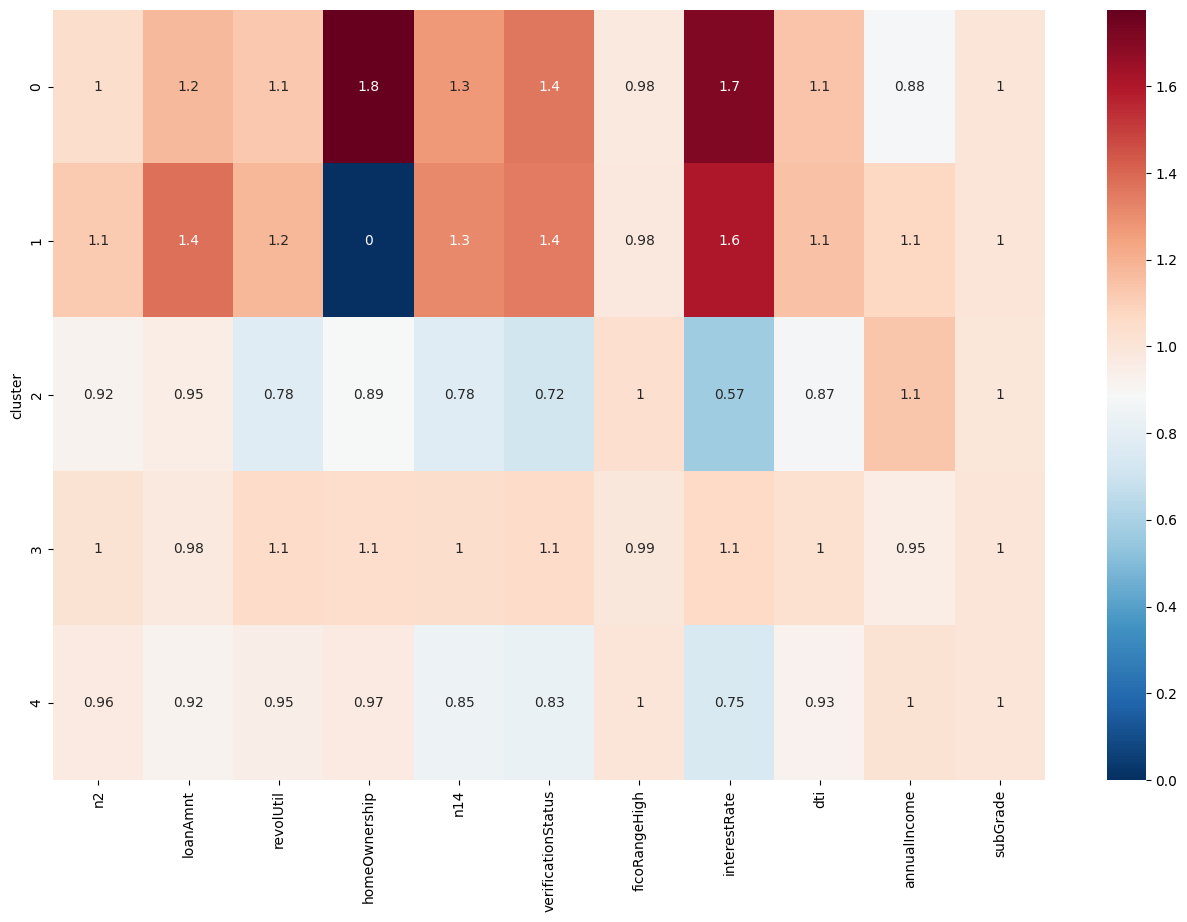

INFO - #################################################
INFO - homeOwnership         1.776547
interestRate          1.712201
verificationStatus    1.362311
n14                   1.274140
loanAmnt              1.174379
dti                   1.142377
revolUtil             1.126782
Name: 0, dtype: float64
INFO - 0.0
INFO - 0.0
INFO - #################################################
INFO - []


cluster,0,1,2,3,4
n2,1.041146,1.121636,0.920775,1.018529,0.964715
loanAmnt,1.174379,1.374395,0.953816,0.976056,0.916931
revolUtil,1.126782,1.182868,0.783347,1.057718,0.950095
homeOwnership,1.776547,0.000000,0.885223,1.053978,0.967272
n14,1.274140,1.317973,0.783146,1.041257,0.846192
verificationStatus,1.362311,1.350430,0.719791,1.055023,0.830120
ficoRangeHigh,0.977717,0.980837,1.036017,0.989887,1.004831
interestRate,1.712201,1.606142,0.569594,1.062603,0.749169
dti,1.142377,1.146709,0.868169,1.029428,0.928406
annualIncome,0.880539,1.075415,1.136820,0.952697,1.016206


In [9]:
new_tgi_df,num_tgi_df,cat_tgi_df,cluster_usr_profile_df = mlModel.cal_tgi(cluster_df,tgi_threshold=1.05)
new_tgi_df.head()
new_tgi_df.style.background_gradient('coolwarm')